# Анализ A/B-теста новой формы оплаты ЖКХ

## Описание проекта

В сервисе оплаты жилищно-коммунальных услуг проведён A/B-тест новой формы с автозаполнением реквизитов.

Воронка оплаты: 1. Открыл форму оплаты → 2. Ввёл реквизиты → 3. Подтвердил платёж → 4. Успешная оплата.

Ключевая метрика: **конверсия из шага 1 в шаг 4**.  
**Гипотеза:** новая форма с автозаполнением реквизитов увеличит долю успешных оплат ЖКХ.  
Необходимо проанализировать результаты A/B-теста и дать рекомендацию: запускать новую форму на всех пользователей или нет.

Длительность теста: 30 дней, с 1 по 30 апреля 2024 года включительно.

## Цели и задачи проекта

**Цель проекта** - оценить влияние новой формы на пользовательскую конверсию в успешную оплату и подготовить рекомендацию о внедрении.

**Задачи проекта:**

1. Выявить и обработать выбросы и некорректные записи, в том числе записи без идентификатора пользователя и аномальные значения.
2. Провести разведочный анализ данных (EDA): изучить данные о пользователях и платежах, структуру таблиц, типы данных и наличие пропусков.
3. Визуализировать результаты анализа.
4. Провести статистическую проверку гипотезы о влиянии новой формы на долю успешных оплат.
5. На основе данных сформулировать рекомендацию для продуктовой команды: запускать новую форму на всех пользователей или нет.

## Описание данных

Все данные находятся в одном Excel-файле `pa_case.xlsx` с двумя листами.

| Лист | Датафрейм | Строк по условию, приблизительно | Содержание |
| --- | --- | --- | --- |
| `Пользователи` | `users` | 1 500 | Группы A/B, тип устройства, город |
| `Платежи` | `payments` | 2 000 | Попытки оплаты ЖКХ за период теста, воронка по шагам |

Фактические размеры таблиц необходимо проверить после загрузки.

## Загрузка и знакомство с данными

In [1]:
# установим необходимые библиотеки
import pandas as pd
import matplotlib.pyplot as plt

!pip install pandas openpyxl
!pip install statsmodels
from statsmodels.stats.proportion import proportions_ztest


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# pагружаем два листа Excel-файла в отдельные датафреймы.
users = pd.read_excel('pa_case.xlsx', sheet_name='Пользователи')
payments = pd.read_excel('pa_case.xlsx', sheet_name='Платежи')

# зафиксируем кол-во строк до предобработки
u_str_start = users.shape[0]
p_str_start = payments.shape[0]

In [3]:
# объединим датафреймы в словарь для дальнейшей работы
dfs_dict = {
    'users': users,
    'payments': payments
}

#### Данные о пользователях

In [4]:
# выведем основную информацию
users.info()

<class 'pandas.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   user_id      1504 non-null   int64
 1   group        1503 non-null   str  
 2   age          1504 non-null   int64
 3   city         1503 non-null   str  
 4   device_type  1504 non-null   str  
dtypes: int64(2), str(3)
memory usage: 58.9 KB


In [5]:
# выведем первые 5 строк
users.head()

,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


По результатам первичного знакомства с данными:

- Датасет `users` содержит **1 504 строки** и **5 столбцов**.
- Пропуски есть в столбцах `group` и `city`. В остальных столбцах пропусков нет.
- Тип `int64` имеют 2 столбца (`user_id`, `age`), строковый тип `str` имеют 3 столбца (`group`, `city`, `device_type`).

#### Данные о платежах

In [6]:
# выведем основную информацию
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   str           
 3   step1_opened     2661 non-null   datetime64[us]
 4   step2_entered    2256 non-null   datetime64[us]
 5   step3_confirmed  1719 non-null   datetime64[us]
 6   step4_success    1522 non-null   datetime64[us]
dtypes: datetime64[us](4), float64(1), int64(1), str(1)
memory usage: 145.7 KB


In [7]:
# выведем первые 5 строк
payments.head()

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


По результатам первичного знакомства с данными:

- Датасет `payments` содержит **2 661 строку** и **7 столбцов**.
- Пропуски есть в столбцах `user_id`, `step2_entered`, `step3_confirmed` и `step4_success`. В остальных столбцах пропусков нет.
- Тип `int64` имеет 1 столбец (`payment_id`), вещественный тип `float64` имеет 1 столбец (`user_id`), строковый тип `str` у 1 столбца (`group`), тип даты и времени `datetime64[us]` имеют 4 столбца (`step1_opened`, `step2_entered`, `step3_confirmed`, `step4_success`).
- Тип данных столбца `user_id` стоит изменить с вещественного на целочисленный.

## Предобработка данных

#### Работа с пропусками

In [8]:
# создадим функцию для анализа пропусков
def show_missing_stats(data):
    missing_stats = pd.DataFrame({
        'Кол-во пропусков': data.isna().sum(),
        'Доля пропусков': data.isna().mean()
    })
    missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0].sort_values(ascending=False, by='Кол-во пропусков')
    
    if missing_stats.empty:
        return None

    return missing_stats.style.format({'Доля пропусков': '{:.4f}'})

# применяем функцию ко всем датафреймам и выводим результат
for name, df in dfs_dict.items():
    print(f'\nДля датасета {name}:')
    styled = show_missing_stats(df)
    if styled is not None:
        display(styled)
    else:
        print('Пропусков в данных нет')


Для датасета users:


,Кол-во пропусков,Доля пропусков
group,1,0.0007
city,1,0.0007



Для датасета payments:


,Кол-во пропусков,Доля пропусков
step4_success,1139,0.4280
step3_confirmed,942,0.3540
step2_entered,405,0.1522
user_id,1,0.0004


Датафрейм **users**:

- По одному пропуску (около 0,07%) найдено в `group` и `city`.
- Строку без группы удаляем, поскольку она не позволяет отнести пользователя к A или B.
- Пропуск города заменяем на 'no city'. Пользователь сохраняется в основной выборке и в анализе устройств и возраста. Из сравнения городов исключаем только категорию 'no city'.

Датафрейм **payments**:

- Пропуски шагов 2-4 оставляем: они могут соответствовать незавершённым попыткам оплаты.
- Одну строку без `user_id` удаляем, поскольку её нельзя связать с уникальным пользователем - единицей расчёта конверсии.

In [9]:
# удаляем строку без группы, а пользователя без города сохраняем
users = users.dropna(subset=['group'])
users['city'] = users['city'].fillna('no city')
payments = payments.dropna(subset=['user_id']).copy()

# переопределяем словарь
dfs_dict = {
    'users': users,
    'payments': payments
}

In [10]:
# повторно применяем функцию ко всем датафреймам и выводим результат
for name, df in dfs_dict.items():
    print(f'\nПосле удаления пропусков для датасета {name}:')
    styled = show_missing_stats(df)
    if styled is not None:
        display(styled)
    else:
        print('Пропусков в данных нет')


После удаления пропусков для датасета users:
Пропусков в данных нет

После удаления пропусков для датасета payments:


,Кол-во пропусков,Доля пропусков
step4_success,1138,0.4278
step3_confirmed,941,0.3538
step2_entered,404,0.1519


После обработки в `users` нет пропусков: неизвестный город обозначен как 'no city'. В `payments` сохранены пропуски последующих шагов воронки, соответствующие незавершённым попыткам в принятой интерпретации событий.

In [11]:
# зафиксируем кол-во строк после работы с пропусками
u_str_null = users.shape[0]
p_str_null = payments.shape[0]

print(f'В датафрейме users было удалено {u_str_start - u_str_null} строк с пропусками.\n\
В датафрейме payments было удалено {p_str_start - p_str_null} строк с пропусками.')

В датафрейме users было удалено 1 строк с пропусками.
В датафрейме payments было удалено 1 строк с пропусками.


#### Работа с типами данных

Для столбца `user_id` из датафрейма payments изменим тип с `float64` на `int64`. Проверим результат.

In [12]:
# заменим тип данных
payments['user_id'] = payments['user_id'].astype('int64')

# проверим результат
payments['user_id'].dtype

dtype('int64')

#### Работа с дубликатами

In [13]:
# создадим функцию для анализа дубликатов
def show_duplicate_stats(data):
    duplicate_stats = pd.DataFrame({
        'Кол-во дубликатов': data.duplicated().sum(),
        'Доля дубликатов': data.duplicated().mean()
    }, index=[0])
    duplicate_stats = duplicate_stats[duplicate_stats['Кол-во дубликатов'] > 0].sort_values(ascending=False, by='Кол-во дубликатов')
    
    if duplicate_stats.empty:
        return None

    return duplicate_stats.style.format({'Доля дубликатов': '{:.4f}'})

# применяем функцию ко всем датафреймам и выводим результат
for name, df in dfs_dict.items():
    print(f'Для датасета {name}:')
    styled = show_duplicate_stats(df)
    if styled is not None:
        display(styled)
    else:
        print('Дубликатов в данных нет\n')

Для датасета users:
Дубликатов в данных нет

Для датасета payments:
Дубликатов в данных нет



In [14]:
# проверим дубликаты по 'user_id' в датафрейме users
print(f'Дубликатов по user_id: {users.duplicated(subset='user_id').sum()}.')

Дубликатов по user_id: 0.


Проверим уникальные значения в категориальных столбцах `city`, `device_type`, `group`.

In [15]:
# уникальные значения города
users['city'].unique()

<StringArray>
['Москва', 'Регион', 'СПб', 'no city']
Length: 4, dtype: str

In [16]:
# уникальные значения устройства
users['device_type'].unique()

<StringArray>
['ios', 'android']
Length: 2, dtype: str

In [17]:
# уникальные значения группы
users['group'].unique()

<StringArray>
['A', 'B']
Length: 2, dtype: str

В категориальных столбцах неявных дубликатов не найдено.

#### Проверка корректности значений

**Временной диапазон**  
Проверим, все ли даты из датафрейма payments попадают в диапазон с 1 до 30 апреля 2024 включительно.

In [18]:
for column in ['step1_opened', 'step2_entered', 'step3_confirmed', 'step4_success']:
    if payments[column].min() < pd.to_datetime('2024-04-01'):
        print(f'Данные {column} выходят за нижнюю границу 1 апреля 2024.')
    if payments[column].max() >= pd.to_datetime('2024-05-01'):
        print(f'Данные {column} выходят за верхнюю границу 30 апреля 2024.')
    if payments[column].min() >= pd.to_datetime('2024-04-01') and payments[column].max() <= pd.to_datetime('2024-05-01'):
        print(f'Данные {column} не выходят за границы промежутка.')

Данные step1_opened не выходят за границы промежутка.
Данные step2_entered не выходят за границы промежутка.
Данные step3_confirmed не выходят за границы промежутка.
Данные step4_success не выходят за границы промежутка.


**Выбросы**  
Проверим наличие выбросов в столбце `age` датафрейма users.

In [19]:
# выведем основные статистики
users['age'].describe()

count    1503.000000
mean       32.750499
std         8.411339
min        -5.000000
25%        27.000000
50%        33.000000
75%        38.000000
max       150.000000
Name: age, dtype: float64

В столбце присутствуют аномальные значения: -5, 150. Отсортируем данные, чтобы посмотреть, есть ли еще аномальные значения в области низких и высоких значений или это единичные случаи.

In [20]:
# сортируем столбец 'age'
users['age'].sort_values()

1501     -5
686      20
685      20
3        20
891      20
       ... 
1480     57
459      58
817      60
68       60
1502    150
Name: age, Length: 1503, dtype: int64

Некорректные значения возраста −5 и 150 заменяем на заглушку -1. Пользователей сохраняем в `users`: ошибка в возрасте не является основанием для исключения из анализа оплат, городов и устройств. Заглушку -1 исключаем только из гистограммы и описательных статистик возраста.

In [21]:
# заменяем некорректный возраст на заглушку, сохраняя пользователей
users.loc[users['age'].isin([-5, 150]), 'age'] = -1

#### Вывод по предобработке

Исходные данные содержали 1504 строки в `users` и 2661 строку в `payments`.

Из `users` удалена только 1 строка без группы: осталось 1503 строки. Два некорректных значения возраста (−5 и 150) заменены на `-1`, соответствующие пользователи сохранены. Заглушки исключаются только из анализа распределения по возрасту. Пропуск города заменён на `'no city'`.  
Из `payments` удалена 1 строка без `user_id`: осталось 2660 строк. Идентификаторы пользователей приведены к целочисленному типу. Полных дубликатов и повторяющихся `user_id` в таблице пользователей не найдено. Даты событий находятся в пределах апреля 2024 года.

## Корректность проведения теста

Проверим распределение участников на группы:
- есть ли участники, попавшие в обе группы
- сравним размеры групп
- исследуем распределение по категориальным признакам `city` и `device_type`, а также по значениям поля `age`

In [22]:
# разделим пользователей на группы A и B
a = payments[payments['group'] == 'A']['user_id']
b = payments[payments['group'] == 'B']['user_id']

intersection = list(set(a) & set(b))
print(f'Пользователи, попавшие в обе группы: {intersection}')

Пользователи, попавшие в обе группы: [1010]


In [23]:
# удалим этого пользователя
users = users[users['user_id'] != 1010]
payments = payments[payments['user_id'] != 1010]
a = a[a != 1010]
b = b[b != 1010]

In [24]:
# считем размеры групп
unique_a = a.nunique()
unique_b = b.nunique()

sum_ab = unique_a + unique_b
share_a = unique_a / sum_ab
share_b = unique_b / sum_ab

print(f'В группах A и B по {unique_a} и {unique_b} пользователей соответственно. \
Соотношение по группам {round(share_a * 100, 2)}% к {round(share_b * 100, 2)}%.')

В группах A и B по 750 и 750 пользователей соответственно. Соотношение по группам 50.0% к 50.0%.


#### Распределение по группам внутри признаков

In [25]:
# для анализа городов исключаем заглушку только из отдельной выборки
users_city = users[users['city'] != 'no city']

# исследуем распределение в группах по регионам
group_city_counts = (
    users_city.groupby(['city', 'group'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

# доля группы среди всех пользователей того же региона
group_city_percent = (
    group_city_counts.div(group_city_counts.sum(axis=1), axis=0) * 100
).round(2)

# сохраняем абсолютные значения и проценты в одном датафрейме
group_city = pd.concat(
    {'Кол-во пользователей': group_city_counts, 'Доля, %': group_city_percent},
    axis=1
)
group_city

Кол-во пользователей      Доля, %       
group                     A    B       A      B
city                                           
Москва                  287  306   48.40  51.60
Регион                  268  246   52.14  47.86
СПб                     195  199   49.49  50.51

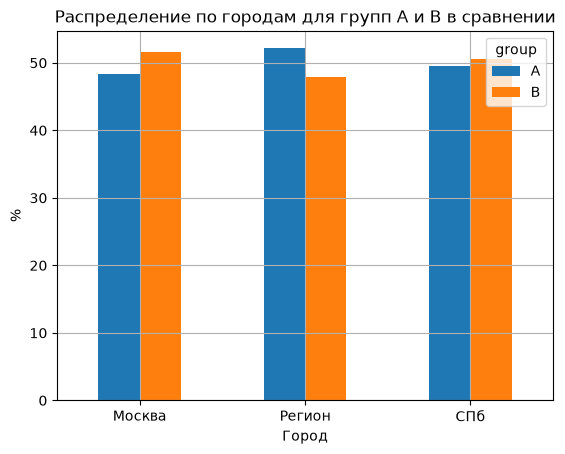

In [26]:
# построим диаграмму с процентным соотношением
group_city_percent.plot(kind='bar',
                legend=True,
                title='Распределение по городам для групп A и B в сравнении',
                xlabel='Город',
                ylabel='%',
                rot=0)
plt.grid()
plt.show()

In [27]:
# исследуем распределение в группах по устройствам
group_device_counts = (
    users.groupby(['device_type', 'group'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

# доля группы среди всех пользователей того же устройства
group_device_percent = (
    group_device_counts.div(group_device_counts.sum(axis=1), axis=0) * 100
).round(2)

# сохраняем абсолютные значения и проценты в одном датафрейме
group_device = pd.concat(
    {'Кол-во пользователей': group_device_counts, 'Доля, %': group_device_percent},
    axis=1
)
group_device

Кол-во пользователей      Доля, %       
group                          A    B       A      B
device_type                                         
android                      407  369   52.45  47.55
ios                          344  382   47.38  52.62

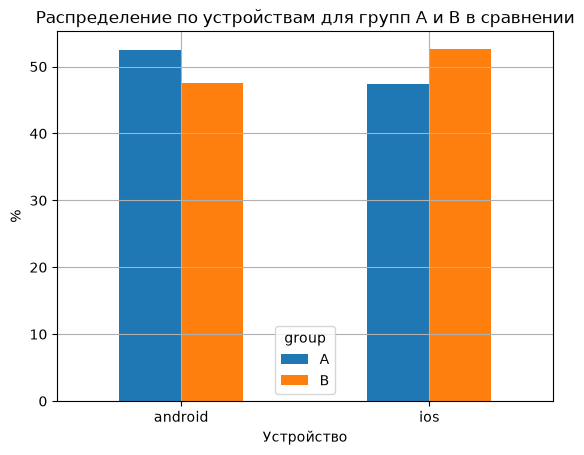

In [28]:
# построим диаграмму с процентным соотношением
group_device_percent.plot(kind='bar',
                legend=True,
                title='Распределение по устройствам для групп A и B в сравнении',
                xlabel='Устройство',
                ylabel='%',
                rot=0)
plt.grid()
plt.show()

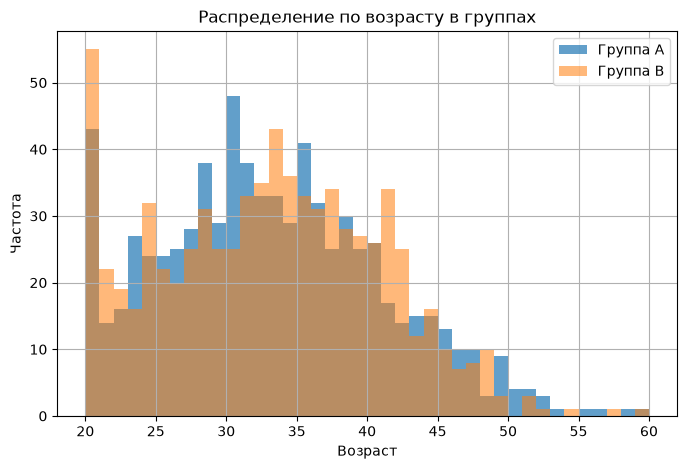

In [29]:
# исключаем заглушку только из выборки для анализа возраста
users_age = users[users['age'] != -1]

# разделим пользователей с корректным возрастом по группам
group_a = users_age[users_age['group'] == 'A']
group_b = users_age[users_age['group'] == 'B']

# построим гистограмму распределения по возрасту в группах
plt.figure(figsize = (8, 5))
plt.hist(group_a['age'], bins=40, alpha=0.7, label='Группа A')
plt.hist(group_b['age'], bins=40, alpha=0.55, label='Группа B')
plt.title('Распределение по возрасту в группах')
plt.xlabel('Возраст')
plt.ylabel('Частота')
plt.grid()
plt.legend()
plt.show()

In [30]:
# выведем основные статистки распределений
df = pd.DataFrame({'Группа A': round(group_a['age'].describe(), 2),
                   'Группа B': round(group_b['age'].describe(), 2)})
df

,Группа A,Группа B
count,750.00,750.00
mean,32.75,32.65
std,7.82,7.78
min,20.00,20.00
25%,27.00,27.00
50%,32.00,33.00
75%,38.00,38.00
max,60.00,60.00


### Вывод о распределении по группам

После исключения пользователя, попавшего в обе группы, в таблице `users` осталось 1502 пользователя - по 751 в группах A и B (**50/50**). Среди открывших форму в `payments` - по 750 пользователей в каждой группе. Два пользователя с заглушкой возраста -1 сохранены в `users`, но платежей у них нет, поэтому на пользовательскую конверсию они не влияют.

В анализе городов участвует 1501 пользователь с известным городом; категория 'no city' исключена только из этого сравнения. Внутри каждого города доля A составляет от **48,40%** до **52,14%**, доля B - от **47,86%** до **51,60%**. Распределение участников между вариантами в городах близко к равному.

Среди пользователей Android **52,45%** относятся к группе A и **47,55%** - к B. Среди пользователей iOS - **47,38%** и **52,62%** соответственно. Распределение близко к равному 50/50.

В анализе возраста участвуют 1500 пользователей с корректным возрастом - по 750 в каждой группе. Два значения -1 исключены из гистограммы и описательных статистик возраста. Возрастные распределения на гистограммах визуально близки: основная масса наблюдений в обеих группах приходится на одинаковый диапазон возрастов. Также статистики распределений (среднее, медиана, 25 и 75 перцентили) практически идентичны.

В целом группы одинаковы по численности и близки по городскому, возрастному и по составу устройств.

## Анализ A/B теста

Сравним конверсию из шага 1 в шаг 4 в группах A и B.

Конверсия рассчитывается как число уникальных пользователей хотя бы с одной успешной оплатой за период, делённое на число уникальных пользователей, открывших форму. Каждый пользователь учитывается один раз независимо от количества попыток. Согласно продуктовой гипотезе, новая форма должна повысить этот показатель, поэтому в группе B это значение должно быть выше.

In [31]:
# считаем пользователей хотя бы с одной успешной оплатой
purchase_a = payments[(payments['group']=='A') & ~(payments['step4_success'].isna())]['user_id'].nunique()
purchase_b = payments[(payments['group']=='B') & ~(payments['step4_success'].isna())]['user_id'].nunique()


# считаем конверсию
conv_a = purchase_a / unique_a
conv_b = purchase_b / unique_b

print(f'Для групп A и B конверсия равна {round(conv_a * 100, 1)}% и {round(conv_b * 100, 1)}% соответственно.')

Для групп A и B конверсия равна 65.7% и 80.4% соответственно.


Конверсии из открытия формы в успешную оплату сравним односторонним z-тестом пропорций при уровне значимости 5%. Сформулируем следующие гипотезы:  

**Нулевая гипотеза H₀:** конверсия в оплату в группе B не выше, чем в группе A (pA ≥ pB).  
**Альтернативная гипотеза H₁:** конверсия в группе B выше, чем в группе A (pA < pB).

In [32]:
# считаем число успехов и размер всей выборки
m_a = purchase_a
m_b = purchase_b
n_a = unique_a
n_b = unique_b

# считаем вероятности
p_a, p_b = m_a / n_a, m_b / n_b

if (p_a*n_a > 10)and((1-p_a)*n_a > 10)and(p_b*n_b > 10)and((1-p_b)*n_b > 10):
    print('Предпосылка о достаточном количестве данных выполняется.')
else:
    print('Предпосылка о достаточном количестве данных НЕ выполняется.')

Предпосылка о достаточном количестве данных выполняется.


In [33]:
# уровень значимости
alpha = 0.05

# статистический тест
stat_ztest, p_value = proportions_ztest(
    [m_a, m_b],
    [n_a, n_b],
    alternative='smaller'
)

if p_value >= alpha:
    print(f'p-value = {p_value}')
    print('Недостаточно оснований утверждать, что конверсия в группе B выше A.')
else:
    print(f'p-value = {p_value}')
    print('Нулевая гипотеза отвергнута. Конверсия в группе B больше, чем в группе A.')

p-value = 7.64799693332123e-11
Нулевая гипотеза отвергнута. Конверсия в группе B больше, чем в группе A.


### Вывод по результатам статистического теста

Успешной оплаты достигли 65,73% пользователей группы A и 80,40% пользователей группы B. Абсолютная разница составляет **14,67 процентного пункта**, относительный прирост - **22,31%**.

Односторонний z-тест двух долей дал **p-value ≈ 7,65 × 10⁻¹¹**, что существенно меньше уровня значимости 0,05. **Нулевая гипотеза отвергается**: пользовательская конверсия в группе B статистически значимо выше, чем в A. Результат поддерживает продуктовую гипотезу о повышении конверсии при использовании новой формы.

## Итоговые рекомендации

На основе результатов проведенного тестирования рекомендуется внедрение новой формы оплаты ЖКХ. В группе B пользовательская конверсия из открытия формы в успешную оплату составила **80,40%** против **65,73%** в A. Прирост равен **14,67 п.п.**, или **22,31%** относительно A, и статистически значим при уровне значимости 5%.

1. Постепенно расширять долю пользователей новой формы, отслеживая сохранение роста конверсии.
2. Во время внедрения контролировать технические ошибки, повторные попытки оплаты и время прохождения формы, чтобы оценивать качество пользовательского опыта вместе с конверсией.

Полученный результат показывает преимущество варианта B по ключевой пользовательской метрике и даёт основание для его дальнейшего масштабирования.